# TidalLanes 估计 + 反事实 walkthrough

本 notebook 的模型代码 cell 由 `run_estimation_flat.py` 按段落**原样切分**生成（仅两处改动：路径改为自动向上找 `data_work`；去掉分片续跑的时间预算退出）。每个关键步骤后有一个**检查点 cell**：统计量校验 + 关键图。

公式对照：`Documents/L1_manuscripts/TidalLanes_Model_v4.tex`；数值基准：`data_work/outputs/stage2_endogenous_edgeproj_v2_lcc_gate5_bpr_pos05_v1`（核对报告见 `outputs/estimation_flat_check_v1/COMPARISON_vs_mainline.md`）。

所有均衡解都缓存在 `outputs/estimation_flat_check_v1/_cache/`：命中缓存时 notebook 全程约 1 分钟，删掉该目录则完整重算（本机约 10–45 分钟，取决于 BLAS）。

## 第 0 部分 — 配置

主线实际求解配置（注意 α>0 覆盖后的 damping=0.10 / max_outer=500 / tol=1e-4）。

In [1]:
# -*- coding: utf-8 -*-
"""
TidalLanes 模型估计 + 全部反事实 —— 单文件平铺版（人工核对用）
================================================================

目的
----
把 data_work/src/model/full_estimation/ 的主线流程（run_stage2_gate5.py，
输出 stage2_endogenous_edgeproj_v2_lcc_gate5_bpr_pos05_v1）在一个文件里
按模型公式顺序重写一遍：同一算法、同一常数、同一迭代次序，
数值应与主线输出一致（浮点噪声量级内）。

模型公式出处：Documents/L1_manuscripts/TidalLanes_Model_v4.tex
    §3.2-3.3   路网 Leontief 聚合与 iceberg 成本:
               t_kl = (τ_kl)^{1/θ},  A_kl = t_kl^{-θ} = 1/τ_kl,
               τ_ij^{-θ} = [(I - A)^{-1}]_{ij}
    §3.4       居住/工作选择 (Fréchet θ), 份额方程 (eq_R)(eq_F)
    §6.2       外部校准 (θ, α, β)
    §6.3       拥堵弹性 λ 截面诊断（仅诊断）
    §6.4       fundamentals 反演 (invert_R)(invert_F)
    Def 4.1    均衡条件 (E1)-(E6)

主线配置（= run_stage2_gate5.py 实际运行值，α>0 触发 solver_overrides）
    travel cost:  model_input_edgeproj_v2_lcc_gate5_v1, square, AM
    θ=6.83, α=0.05, β=-0.10
    拥堵形式:     anchored, λ_phys=1.1（北京 speed-density 证据）
    外层求解:     damping=0.10, max_outer=500, tol=1e-4
                  （α>0 时 run_alpha_robustness_quick_gate5.POSITIVE_ALPHA_SOLVER
                    覆盖了 CLI 默认的 80/1e-5/0.25 —— 这里直接写死实际用值）
    反演:         kappa=1.0, tol=1.5e-4, max_iter=1800
    tidal 选边:   score_bpr_st

运行
----
    cd data_work
    python3 src/model/full_estimation_flat/run_estimation_flat.py

输出
----
    data_work/outputs/estimation_flat_check_v1/   （目录结构与主线输出相同）
"""
import json
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import linalg as sla

T0 = time.time()
def log(msg):
    print(f"[{time.time()-T0:8.1f}s] {msg}", flush=True)

# 断点续跑：每个均衡解出后缓存到 <OUT>/_cache/<key>.npz，重跑时直接载入。
# 想完全重算就删掉 _cache 目录。FLAT_TIME_BUDGET（秒）用于把长任务切成多次
# 短跑（超过预算就退出，返回码 3；不设则一口气跑完）。
TIME_BUDGET = float(os.environ.get("FLAT_TIME_BUDGET", "1e18"))

# ============================================================================
# 第 0 部分 —— 配置常数（全部写死，与主线一致）
# ============================================================================
# notebook 版：从当前目录向上找 data_work（含 outputs/ 与 src/ 的目录）
DATA_WORK = Path.cwd().resolve()
while not ((DATA_WORK / "outputs").is_dir() and (DATA_WORK / "src").is_dir()):
    assert DATA_WORK != DATA_WORK.parent, "请从 data_work 目录（或其子目录）启动 notebook"
    DATA_WORK = DATA_WORK.parent
VERSION_ID = "model_input_edgeproj_v2_lcc_gate5_v1"
OUT = DATA_WORK / "outputs" / "estimation_flat_check_v1"
GRID_TYPE, PERIOD, OD_POP_COL = "square", "AM", "commuters_road"

# ---- 参数（Step 2, §6.2）----
THETA = 6.83          # Fréchet shape（AA2022 Seattle, 经 ARSW2015）
ALPHA = 0.05          # 工作地生产外部性（主线 pos05：文献中位 gross spillover）
BETA = -0.10          # 居住外部性（AA2022 Seattle）
LAMBDA_PHYS = 1.1     # 主线物理拥堵弹性（北京 speed-density ≈1.1），用于 (E6) anchored
DELTA1_AA = 0.488     # AA Seattle 拥堵回归 δ1，仅用于 exogenous BPR 诊断
LAMBDA_LEGACY = DELTA1_AA / THETA        # 0.07144...，只进 parameters.json 存档
DELTA1_CF2_EXOG = LAMBDA_LEGACY * THETA  # CF2-exog 用 params.lambda_*θ（≈0.488，浮点上略异）

# ---- 求解器设置（主线实际使用值）----
KAPPA = 1.0           # 谱半径保护的统一 iceberg 缩放；gate5 主线全程 kappa=1
DAMPING = 0.10        # 外层 log 空间阻尼
MAX_OUTER = 500       # 外层最大迭代
TOL_OUTER = 1e-4      # 外层收敛容差 max|Δlog τ|
INNER_MAX, INNER_TOL = 400, 1e-8    # (eq_R)(eq_F) 份额内层
MA_MAX, MA_TOL = 400, 1e-9          # (E4) market access 内层
INV_MAX, INV_TOL = 1800, 1.5e-4     # Step 4 反演
FLOOR_SHARE = 1e-6    # 零人口格子的下限（对 L 而非份额；同 AA 复制版 PLAN.md §5）
EPS = 1e-12
PAIR_MIN_LEN_M = 200.0   # 互逆边对入选的最短长度（双向都要 ≥200m）

## 第 1 部分 — 数据 → primitives（v4 §6.1，表 1）

有向边 $(\tau^{obs}_{k\ell}, \tau^{ff}_{k\ell}, \ell_{k\ell}, n_{k\ell})$，人口 $L^{obs}_{ij},\ L^R_i=\sum_j L_{ij},\ L^F_j=\sum_i L_{ij},\ \bar L$。

In [2]:
# ============================================================================
# 第 1 部分 —— 读数据，构造 primitives（Step 1, §6.1 表1 A/B 面板）
#   有向边:  τ^obs_kl, τ^ff_kl (分钟), ℓ_kl (km), n_kl (车道)
#   人口:    L_ij^obs (道路通勤 OD), L^R_i=Σ_j, L^F_j=Σ_i, L̄=ΣL^R
# ============================================================================
log("Step 1: 读取 QSM parquet")
data_dir = DATA_WORK / "outputs" / VERSION_ID / "data"
nodes = pd.read_parquet(data_dir / f"qsm_input_nodes_{GRID_TYPE}.parquet")
edges = pd.read_parquet(data_dir / f"qsm_input_edges_{GRID_TYPE}.parquet")
od = pd.read_parquet(data_dir / f"qsm_input_od_{GRID_TYPE}.parquet")

# 节点：keep_for_model==1，按 node_i 排序后重编号为连续 0..N-1
nodes = nodes[nodes["keep_for_model"] == 1].copy()
nodes["node_i"] = pd.to_numeric(nodes["node_i"]).astype(int)
nodes = nodes.sort_values("node_i").reset_index(drop=True)
raw_to_new = {int(o): n for n, o in enumerate(nodes["node_i"])}
N = len(nodes)
GRID_IDS = nodes["grid_id"].astype(str).to_numpy()

# 边：AM 期，两端都在保留节点内，τ 有限且 >0
e = edges[edges["period"].astype(str).str.upper() == PERIOD].copy()
e["i"] = pd.to_numeric(e["i"]).astype(int)
e["j"] = pd.to_numeric(e["j"]).astype(int)
e = e[e["i"].isin(raw_to_new) & e["j"].isin(raw_to_new)]
t_obs = pd.to_numeric(e["tau_obs_min"], errors="coerce")
t_ff = pd.to_numeric(e["tau_ff_min"], errors="coerce")
ok = np.isfinite(t_obs) & (t_obs > 0) & np.isfinite(t_ff) & (t_ff > 0)
e = e[ok]
TAU_OBS = t_obs[ok].to_numpy(float)      # τ^obs_kl
TAU_FF = t_ff[ok].to_numpy(float)        # τ^ff_kl
ELL_KM = pd.to_numeric(e["total_link_len_m"], errors="coerce").fillna(0.0).to_numpy(float) / 1000.0
# 车道：lanes_directional 缺失 → lane_est_length_weighted → 全边均值
n_raw = pd.to_numeric(e["lanes_directional"], errors="coerce").to_numpy(float)
fb = pd.to_numeric(e["lane_est_length_weighted"], errors="coerce").to_numpy(float)
n_raw = np.where(np.isfinite(n_raw) & (n_raw > 0), n_raw, fb)
N_KL = np.where(np.isfinite(n_raw) & (n_raw > 0), n_raw, np.nanmean(n_raw))
EDGE_I = e["i"].map(raw_to_new).to_numpy(int)
EDGE_J = e["j"].map(raw_to_new).to_numpy(int)
M = len(EDGE_I)
assert not pd.DataFrame({"i": EDGE_I, "j": EDGE_J}).duplicated().any(), "(i,j) 应唯一"

# 求解器用车道数（原 _resolve_lanes）：非正→中位数，下限 1
_med = float(np.nanmedian(N_KL[np.isfinite(N_KL) & (N_KL > 0)]))
N_KL_SOLVER = np.clip(np.where(np.isfinite(N_KL) & (N_KL > 0), N_KL, _med), 1.0, None)

def resolve_lanes(n):
    """反事实车道向量同样处理：非正→中位数，下限 1。"""
    n = np.asarray(n, float).copy()
    m = float(np.nanmedian(n[np.isfinite(n) & (n > 0)])) if np.any(np.isfinite(n)) else 2.0
    return np.clip(np.where(np.isfinite(n) & (n > 0), n, m), 1.0, None)

# OD → 稠密 N×N
oi = pd.to_numeric(od["origin_node"], errors="coerce")
dj = pd.to_numeric(od["destination_node"], errors="coerce")
wt = pd.to_numeric(od[OD_POP_COL], errors="coerce").fillna(0.0)
ok = oi.notna() & dj.notna()
oi, dj, wt = oi[ok].astype(int), dj[ok].astype(int), wt[ok].to_numpy(float)
ok2 = oi.isin(raw_to_new) & dj.isin(raw_to_new)
oi = oi[ok2].map(raw_to_new).to_numpy(int)
dj = dj[ok2].map(raw_to_new).to_numpy(int)
wt = wt[np.asarray(ok2)]
L_IJ = np.zeros((N, N))
np.add.at(L_IJ, (oi, dj), wt)
L_R_OBS = L_IJ.sum(axis=1)               # L^R_i
L_F_OBS = L_IJ.sum(axis=0)               # L^F_j
LBAR = float(L_R_OBS.sum())              # L̄
log(f"  N={N} 节点, M={M} 有向边, L̄={LBAR:.1f}")

[     0.0s] Step 1: 读取 QSM parquet


[     0.2s]   N=1104 节点, M=2642 有向边, L̄=88110.2


,count,mean,std,min,5%,25%,50%,75%,95%,max
tau_obs_min,2642.0,10.189,5.489,2.384,4.647,6.575,8.711,12.026,20.875,52.266
tau_ff_min,2642.0,8.011,3.428,2.556,4.024,5.653,7.108,9.476,15.201,23.369
tau_obs/tau_ff,2642.0,1.276,0.453,0.428,0.984,1.054,1.149,1.341,1.981,9.455
ell_km,2642.0,5.291,1.907,2.526,3.240,3.883,4.757,6.133,9.503,11.498
n_kl,2642.0,3.200,0.950,2.000,2.000,2.102,3.366,4.000,4.112,6.000


有互逆边的方向边占比: 90.3%
tau_obs < tau_ff 的边占比（上游 free-flow floor 口径问题，已知≈8%）: 8.3%
OD: 正流量格对 83,030 个, 同格(对角)通勤占比 8.0%
零居民节点 10 个, 零就业节点 9 个（反演时 floor）


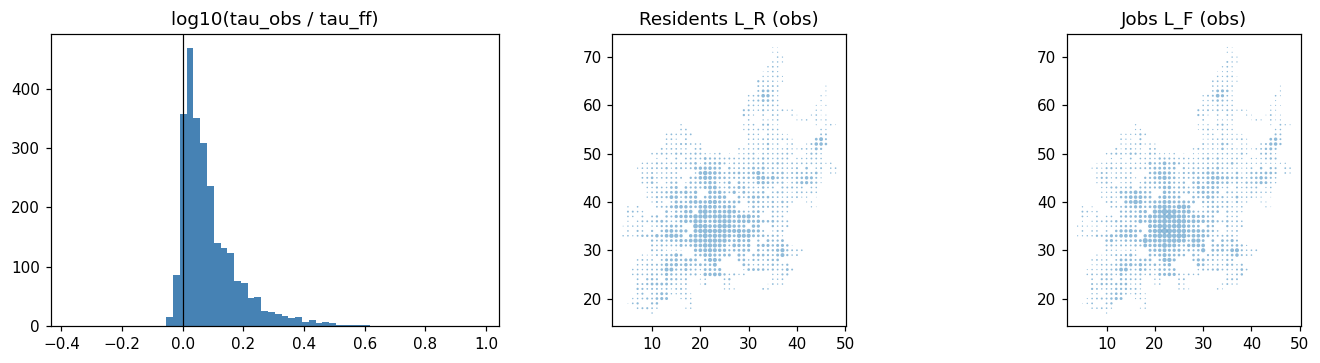

In [3]:
# ———— 检查点 1：primitives ————
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams["figure.dpi"] = 110

_p = [g.split("_") for g in GRID_IDS]
GX = np.array([int(t[1]) if len(t) >= 3 else 0 for t in _p], float)
GY = np.array([int(t[2]) if len(t) >= 3 else 0 for t in _p], float)
_pairset = {(int(EDGE_I[k]), int(EDGE_J[k])) for k in range(M)}
_has_rev = np.array([(int(EDGE_J[k]), int(EDGE_I[k])) in _pairset for k in range(M)])
ratio_of = TAU_OBS / TAU_FF

display(pd.DataFrame({"tau_obs_min": TAU_OBS, "tau_ff_min": TAU_FF, "tau_obs/tau_ff": ratio_of,
                      "ell_km": ELL_KM, "n_kl": N_KL})
        .describe(percentiles=[.05, .25, .5, .75, .95]).T.round(3))
print(f"有互逆边的方向边占比: {_has_rev.mean():.1%}")
print(f"tau_obs < tau_ff 的边占比（上游 free-flow floor 口径问题，已知≈8%）: {(TAU_OBS < TAU_FF).mean():.1%}")
print(f"OD: 正流量格对 {int((L_IJ > 0).sum()):,} 个, 同格(对角)通勤占比 {np.trace(L_IJ) / LBAR:.1%}")
print(f"零居民节点 {int((L_R_OBS == 0).sum())} 个, 零就业节点 {int((L_F_OBS == 0).sum())} 个（反演时 floor）")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(np.log10(ratio_of), bins=60, color="steelblue")
ax[0].axvline(0, color="k", lw=.8); ax[0].set_title("log10(tau_obs / tau_ff)")
for a, val, ttl in [(ax[1], L_R_OBS, "Residents L_R (obs)"), (ax[2], L_F_OBS, "Jobs L_F (obs)")]:
    a.scatter(GX, GY, s=np.sqrt(val) * .35 + .2, alpha=.5, lw=0)
    a.set_title(ttl); a.set_aspect("equal")
plt.tight_layout(); plt.show()

## 第 2–3 部分 — 均衡构件与求解器（v4 Def 4.1）

$$(E1)\ \tau_{ij}^{-\theta}=[(I-A)^{-1}]_{ij},\ A_{k\ell}=1/\tau_{k\ell}\qquad(eq_R)\ (l_i^R)^{1-\beta\theta}=\chi\,\bar u_i^\theta\textstyle\sum_j \tau_{ij}^{-\theta}\bar A_j^\theta (l_j^F)^{\alpha\theta}$$
$$(E4)\ \Pi_i^{-\theta}=\textstyle\sum_j \tau_{ij}^{-\theta}L^F_j P_j^{\theta}\qquad(E5)\ \Xi_{k\ell}=t_{k\ell}^{-\theta}P_k^{-\theta}\Pi_\ell^{-\theta}\qquad(E6)\ \tau_{k\ell}=\max\big(\tau^{ff},\ \tau^{obs}\,[(\Xi/\Xi^{obs})(n^{obs}/n)]^{\lambda}\big)$$
福利（gauge-free）：$\bar W^\theta=\sum_{ij}\tau_{ij}^{-\theta}\,\bar u_i^\theta (L_i^R)^{\beta\theta}\,\bar A_j^\theta (L_j^F)^{\alpha\theta}$。

In [4]:
# ============================================================================
# 第 2 部分 —— 均衡的四个基础构件（每个都对应一条模型公式）
# ============================================================================
def tau_inv_theta_matrix(tau_min):
    """(E1)+§3.3:  A_kl = t_kl^{-θ} = 1/(κ·τ_kl)；τ_ij^{-θ} = [(I-A)^{-1}]_ij。
    稠密求解 (I-A)X=I；元素下限 EPS。κ=1（gate5 主线，行和<1 自动满足）。"""
    A = np.zeros((N, N))
    np.add.at(A, (EDGE_I, EDGE_J), 1.0 / np.clip(KAPPA * tau_min, EPS, None))
    X = sla.solve(np.eye(N) - A, np.eye(N), check_finite=False)
    return np.clip(X, EPS, None)

def solve_shares(tau_inv, ubar_theta, abar_theta, chi):
    """份额方程 (eq_R)(eq_F)，Gauss-Seidel 交替不动点：
       (l_i^R)^{1-βθ} = χ ū_iθ Σ_j τ_ij^{-θ} Ā_jθ (l_j^F)^{αθ}
       (l_j^F)^{1-αθ} = χ Ā_jθ Σ_i τ_ij^{-θ} ū_iθ (l_i^R)^{βθ}
       每步都重新归一化 Σl=1。"""
    l_R = np.full(N, 1.0 / N)
    l_F = np.full(N, 1.0 / N)
    for _ in range(INNER_MAX):
        rhs_R = chi * ubar_theta * (tau_inv @ (abar_theta * l_F ** (ALPHA * THETA)))
        l_R_new = np.clip(rhs_R, EPS, None) ** (1.0 / (1.0 - BETA * THETA))
        l_R_new = l_R_new / l_R_new.sum()
        rhs_F = chi * abar_theta * (tau_inv.T @ (ubar_theta * l_R_new ** (BETA * THETA)))
        l_F_new = np.clip(rhs_F, EPS, None) ** (1.0 / (1.0 - ALPHA * THETA))
        l_F_new = l_F_new / l_F_new.sum()
        d = max(float(np.max(np.abs(np.log(np.clip(l_R_new, EPS, None)) - np.log(np.clip(l_R, EPS, None))))),
                float(np.max(np.abs(np.log(np.clip(l_F_new, EPS, None)) - np.log(np.clip(l_F, EPS, None))))))
        l_R, l_F = l_R_new, l_F_new
        if d < INNER_TOL:
            break
    return l_R, l_F

def market_access(tau_inv, l_R, l_F):
    """(E4) 市场可达性，交替更新：
       Π_i^{-θ} = Σ_j τ_ij^{-θ} L_j^F P_j^{θ}
       P_j^{-θ} = Σ_i τ_ij^{-θ} L_i^R Π_i^{θ}"""
    L_R, L_F = l_R * LBAR, l_F * LBAR
    Pi, P = np.ones(N), np.ones(N)
    for _ in range(MA_MAX):
        Pi_new = np.clip(tau_inv @ (L_F * P ** THETA), EPS, None) ** (-1.0 / THETA)
        P_new = np.clip(tau_inv.T @ (L_R * Pi_new ** THETA), EPS, None) ** (-1.0 / THETA)
        d = max(float(np.max(np.abs(np.log(Pi_new / np.clip(Pi, EPS, None))))),
                float(np.max(np.abs(np.log(P_new / np.clip(P, EPS, None))))))
        Pi, P = Pi_new, P_new
        if d < MA_TOL:
            break
    return Pi, P

def edge_traffic(tau_min, Pi, P):
    """(E5) 有向边流量：Ξ_kl = t_kl^{-θ} · P_k^{-θ} · Π_l^{-θ}
    （k=边尾=EDGE_I, l=边头=EDGE_J；t_kl^{-θ}=1/τ_kl，
      按原代码先算 t=τ^{1/θ} 再取 -θ 次方，保持浮点路径一致）"""
    t = tau_min ** (1.0 / THETA)
    return (t ** (-THETA)) * (P[EDGE_I] ** (-THETA)) * (Pi[EDGE_J] ** (-THETA))

def welfare_wbar(tau_inv, l_R, l_F, ubar_theta, abar_theta):
    """福利（gauge-free Fréchet 分母，2026-07-01 welfare gauge 修正后的主口径）：
       W̄^θ = Σ_i Σ_j τ_ij^{-θ} · [ū_iθ (L_i^R)^{βθ}] · [Ā_jθ (L_j^F)^{αθ}]"""
    u = ubar_theta * np.clip(l_R * LBAR, EPS, None) ** (BETA * THETA)
    w = abar_theta * np.clip(l_F * LBAR, EPS, None) ** (ALPHA * THETA)
    W_theta = float(np.sum(tau_inv * u[:, None] * w[None, :]))
    return W_theta ** (1.0 / THETA) if W_theta > 0 else np.nan

# ---- (E6) anchored 拥堵技术（gate5 主线；"semi-lock"：水平锚在 τ^obs）----
# τ_kl = max( τ^ff_kl , τ^obs_kl · [ (Ξ_kl/Ξ^obs_kl)·(n^obs_kl/n_kl) ]^{λ_phys} )
# Ξ^obs 来自"观测锚定"运行（第 4 部分算出后填入这三个全局量）
XI_OBS = None          # Ξ^obs_kl：τ 固定在 τ^obs 时模型隐含的边流量
N_OBS = None           # n^obs_kl：观测车道（解析后）
TAU_ANCHOR = None      # τ^obs_kl 锚

def tau_congestion_anchored(tau_ff, Xi, n_kl):
    dev = (np.clip(Xi / np.clip(XI_OBS, EPS, None), EPS, None)
           * np.clip(N_OBS / np.clip(n_kl, EPS, None), EPS, None))
    return np.maximum(tau_ff, TAU_ANCHOR * dev ** LAMBDA_PHYS)

In [5]:
# ============================================================================
# 第 3 部分 —— 均衡求解器（Def 4.1 外层不动点；全部反事实共用）
# ============================================================================
def solve_equilibrium(ubar_theta, abar_theta, chi, *, tau_min_init, endogenous,
                      n_kl=None, tau_ff=None, l_R_pin=None, l_F_pin=None,
                      label="equilibrium"):
    """外层在 τ_kl 上迭代（log 空间阻尼 DAMPING）：
         τ → (E1) τ_ij^{-θ} → (eq_R)(eq_F) 份额 → (E4) (Π,P) → (E5) Ξ
           → (E6) τ_new → 阻尼更新，直到 max|Δlog τ| < TOL_OUTER
       endogenous=False: τ 固定在 tau_min_init，只解份额/可达性（=Stage-1 型固定成本解）
       l_R_pin/l_F_pin:  短期模式，份额钉在基线（τ 仍可内生更新）"""
    n_use = N_KL_SOLVER if n_kl is None else resolve_lanes(n_kl)
    tau_ff_use = TAU_FF if tau_ff is None else np.asarray(tau_ff, float)
    tau_min = np.asarray(tau_min_init, float).copy()
    pinned = l_R_pin is not None and l_F_pin is not None
    if pinned:
        l_R_pin = np.clip(np.asarray(l_R_pin, float), EPS, None); l_R_pin = l_R_pin / l_R_pin.sum()
        l_F_pin = np.clip(np.asarray(l_F_pin, float), EPS, None); l_F_pin = l_F_pin / l_F_pin.sum()

    converged, last_delta, it = False, np.inf, 0
    for it in range(1, MAX_OUTER + 1):
        tau_inv = tau_inv_theta_matrix(tau_min)
        if pinned:
            l_R, l_F = l_R_pin, l_F_pin
        else:
            l_R, l_F = solve_shares(tau_inv, ubar_theta, abar_theta, chi)
        Pi, P = market_access(tau_inv, l_R, l_F)
        Xi = edge_traffic(tau_min, Pi, P)
        if not endogenous:
            converged, last_delta = True, 0.0
            break
        tau_new = tau_congestion_anchored(tau_ff_use, Xi, n_use)
        log_old = np.log(np.clip(tau_min, EPS, None))
        tau_damp = np.exp(DAMPING * np.log(np.clip(tau_new, EPS, None)) + (1.0 - DAMPING) * log_old)
        last_delta = float(np.max(np.abs(np.log(tau_damp) - log_old)))
        tau_min = tau_damp
        if last_delta < TOL_OUTER:
            converged = True
            break

    # 按最终 τ 再完整算一遍（与原 equilibrium_solve.py 末段一致）
    tau_inv = tau_inv_theta_matrix(tau_min)
    if pinned:
        l_R, l_F = l_R_pin, l_F_pin
    else:
        l_R, l_F = solve_shares(tau_inv, ubar_theta, abar_theta, chi)
    Pi, P = market_access(tau_inv, l_R, l_F)
    Xi = edge_traffic(tau_min, Pi, P)
    Wbar = welfare_wbar(tau_inv, l_R, l_F, ubar_theta, abar_theta)
    u = ubar_theta * np.clip(l_R * LBAR, EPS, None) ** (BETA * THETA)
    Wpi_theta = float(np.sum(u * np.clip(Pi, EPS, None) ** (-THETA)))   # 旧 Π-gauge 口径，仅诊断
    return {
        "label": label, "tau_min_kl": tau_min, "Xi_kl": Xi, "tau_inv": tau_inv,
        "l_R": l_R, "l_F": l_F, "Pi_i": Pi, "P_j": P,
        "Wbar": float(Wbar),
        "Wbar_pi_raw": float(Wpi_theta ** (1.0 / THETA)) if Wpi_theta > 0 else float("nan"),
        "n_outer": it, "converged": converged, "max_log_change": last_delta,
        "endogenous": endogenous,
    }

CACHE_DIR = DATA_WORK / "outputs" / "estimation_flat_check_v1" / "_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def solve_cached(key, **kw):
    """solve_equilibrium 的缓存包装：命中 _cache/<key>.npz 直接载入
    （tau_inv 由缓存的 τ 现算一次，与求解末段完全相同），否则求解并缓存。"""
    f = CACHE_DIR / (key + ".npz")
    if f.exists():
        z = np.load(f)
        eq = {"label": str(z["label"]), "tau_min_kl": z["tau_min_kl"], "Xi_kl": z["Xi_kl"],
              "l_R": z["l_R"], "l_F": z["l_F"], "Pi_i": z["Pi_i"], "P_j": z["P_j"],
              "Wbar": float(z["Wbar"]), "Wbar_pi_raw": float(z["Wbar_pi_raw"]),
              "n_outer": int(z["n_outer"]), "converged": bool(z["converged"]),
              "max_log_change": float(z["max_log_change"]), "endogenous": bool(z["endogenous"])}
        eq["tau_inv"] = tau_inv_theta_matrix(eq["tau_min_kl"])
        return eq
    eq = solve_equilibrium(**kw)
    np.savez_compressed(f, **{k: v for k, v in eq.items() if k != "tau_inv"})
    return eq

def write_eq(eq, out_dir):
    """按原格式保存均衡（npz 数组 + meta json）。"""
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(out_dir / "equilibrium_arrays.npz",
                        tau_min_kl=eq["tau_min_kl"],
                        t_kl_iceberg=eq["tau_min_kl"] ** (1.0 / THETA),
                        Xi_kl=eq["Xi_kl"], l_R=eq["l_R"], l_F=eq["l_F"],
                        Pi_i=eq["Pi_i"], P_j=eq["P_j"])
    meta = {"label": eq["label"], "Wbar": eq["Wbar"], "Wbar_pi_raw": eq["Wbar_pi_raw"],
            "n_outer": eq["n_outer"], "converged": eq["converged"],
            "max_log_change": eq["max_log_change"],
            "endogenous_congestion": eq["endogenous"], "kappa": KAPPA,
            "congestion_form": "anchored", "congestion_lambda": LAMBDA_PHYS}
    (out_dir / "equilibrium_meta.json").write_text(json.dumps(meta, indent=2, default=float))

## 第 4 部分 — 反演 fundamentals（v4 §6.4）

交替更新 $(v,w)=(\bar u^\theta,\bar A^\theta)$，几何均值归一（只在两侧人口均为正的 valid 节点上），$\chi$ 最后回收；残差为复现观测份额的 log 差。

In [6]:
# ============================================================================
# 第 4 部分 —— Step 4: 反演 fundamentals (ū_iθ, Ā_jθ, χ)（§6.4）
#   (invert_R): (l_i^{R,obs})^{1-βθ} = χ Σ_j τ_ij^{-θ} ū_iθ Ā_jθ (l_j^{F,obs})^{αθ}
#   (invert_F): (l_j^{F,obs})^{1-αθ} = χ Σ_i τ_ij^{-θ} ū_iθ Ā_jθ (l_i^{R,obs})^{βθ}
#   交替更新 (v,w)=(ūθ,Āθ)，每步几何均值归一（在 valid 节点上），χ 最后回收。
# ============================================================================
log("Step 4: 反演 fundamentals")
L_R_f = np.maximum(L_R_OBS, FLOOR_SHARE)     # 零人口格子加下限，log 才有限
L_F_f = np.maximum(L_F_OBS, FLOOR_SHARE)
l_R_obs = L_R_f / L_R_f.sum()
l_F_obs = L_F_f / L_F_f.sum()
VALID = (L_R_OBS > 0) & (L_F_OBS > 0)        # 两侧都有人的节点才提供识别信息

def gmean_norm(x):
    """x / gmean(x[VALID])，下限 1e-30（原 _gmean_normalize）。"""
    x = np.clip(np.asarray(x, float), 1e-30, None)
    g = float(np.exp(np.mean(np.log(x[VALID]))))
    return x / g if np.isfinite(g) and g > 0 else x

TAU_INV_OBS = tau_inv_theta_matrix(TAU_OBS)  # τ_ij^{obs,-θ}，τ^obs 固定所以只算一次
pR, pF = 1.0 - BETA * THETA, 1.0 - ALPHA * THETA
qR, qF = BETA * THETA, ALPHA * THETA
v = np.ones(N)      # v_i = ū_i^θ
w = np.ones(N)      # w_j = Ā_j^θ
inv_converged, inv_delta = False, np.inf
for inv_it in range(1, INV_MAX + 1):
    a = TAU_INV_OBS @ (w * l_F_obs ** qF)                    # a_i = Σ_j τ^{-θ}(l^F)^{αθ}w_j
    v_new = gmean_norm((l_R_obs ** pR) / np.clip(a, EPS, None))
    b = TAU_INV_OBS.T @ (v_new * l_R_obs ** qR)              # b_j = Σ_i τ^{-θ}(l^R)^{βθ}v_i
    w_new = gmean_norm((l_F_obs ** pF) / np.clip(b, EPS, None))
    # 收敛判据：χ 在 valid 节点上应为常数 → std(log χ_R), std(log χ_F)
    a_chk = TAU_INV_OBS @ (w_new * l_F_obs ** qF)
    b_chk = TAU_INV_OBS.T @ (v_new * l_R_obs ** qR)
    chi_R = (l_R_obs ** pR) / np.clip(v_new * a_chk, EPS, None)
    chi_F = (l_F_obs ** pF) / np.clip(w_new * b_chk, EPS, None)
    inv_delta = float(max(np.std(np.log(np.clip(chi_R[VALID], EPS, None))),
                          np.std(np.log(np.clip(chi_F[VALID], EPS, None)))))
    v, w = v_new, w_new
    if inv_delta < INV_TOL:
        inv_converged = True
        break

# χ = valid 节点上 (χ_R, χ_F) 的对数均值的几何平均
a = TAU_INV_OBS @ (w * l_F_obs ** qF)
b = TAU_INV_OBS.T @ (v * l_R_obs ** qR)
chi_R = (l_R_obs ** pR) / np.clip(v * a, EPS, None)
chi_F = (l_F_obs ** pF) / np.clip(w * b, EPS, None)
CHI = float(np.exp(0.5 * (np.mean(np.log(np.clip(chi_R[VALID], EPS, None)))
                          + np.mean(np.log(np.clip(chi_F[VALID], EPS, None))))))
UBAR = v            # ū_i^θ（几何均值≈1）
ABAR = w            # Ā_j^θ
# 残差：反演出的 (v,w,χ) 复现观测份额的 log 差（ass:obs_eq 下应≈0）
l_R_pred = (CHI * v * a) ** (1.0 / pR); l_R_pred = l_R_pred / l_R_pred.sum()
l_F_pred = (CHI * w * b) ** (1.0 / pF); l_F_pred = l_F_pred / l_F_pred.sum()
RESID_R = np.zeros(N); RESID_F = np.zeros(N)
RESID_R[VALID] = np.log(np.clip(l_R_pred[VALID], EPS, None)) - np.log(np.clip(l_R_obs[VALID], EPS, None))
RESID_F[VALID] = np.log(np.clip(l_F_pred[VALID], EPS, None)) - np.log(np.clip(l_F_obs[VALID], EPS, None))
log(f"  反演 {'收敛' if inv_converged else '未收敛'} @ iter={inv_it}, delta={inv_delta:.3e}, chi={CHI:.6e}")

[     1.9s] Step 4: 反演 fundamentals


[     2.7s]   反演 收敛 @ iter=455, delta=1.494e-04, chi=7.257629e-06


chi = 7.257629e-06   迭代 455   收敛 True   判据 std(log chi) = 1.49e-04
识别节点(两侧人口>0): 1092/1104
复现残差: max|resid_R| = 2.93e-03, max|resid_F| = 1.78e-15  (ass:obs_eq 下应≈0)
gmean 归一检查: gmean(ubar_theta[valid]) = 1.000000 (应=1), gmean(abar_theta[valid]) = 1.000000


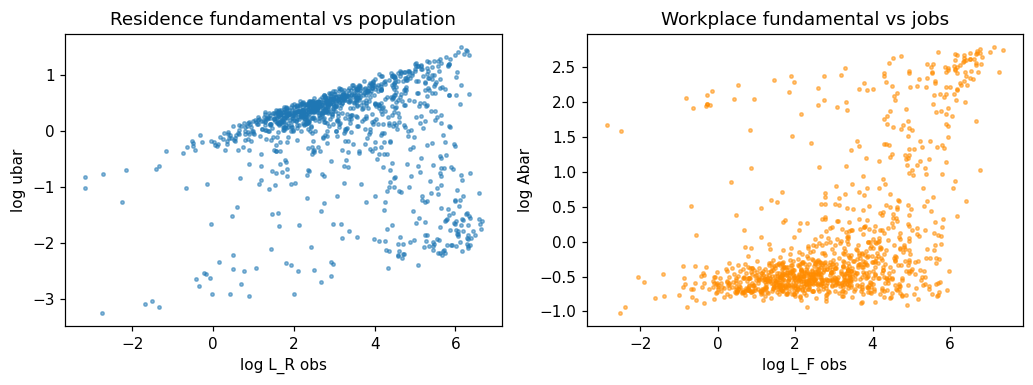

In [7]:
# ———— 检查点 4：反演质量 ————
print(f"chi = {CHI:.6e}   迭代 {inv_it}   收敛 {inv_converged}   判据 std(log chi) = {inv_delta:.2e}")
print(f"识别节点(两侧人口>0): {int(VALID.sum())}/{N}")
print(f"复现残差: max|resid_R| = {np.abs(RESID_R).max():.2e}, max|resid_F| = {np.abs(RESID_F).max():.2e}  (ass:obs_eq 下应≈0)")
print(f"gmean 归一检查: gmean(ubar_theta[valid]) = {np.exp(np.mean(np.log(UBAR[VALID]))):.6f} (应=1), "
      f"gmean(abar_theta[valid]) = {np.exp(np.mean(np.log(ABAR[VALID]))):.6f}")

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
ax[0].scatter(np.log(L_R_OBS[VALID]), np.log(UBAR[VALID]) / THETA, s=5, alpha=.5)
ax[0].set_xlabel("log L_R obs"); ax[0].set_ylabel("log ubar"); ax[0].set_title("Residence fundamental vs population")
ax[1].scatter(np.log(L_F_OBS[VALID]), np.log(ABAR[VALID]) / THETA, s=5, alpha=.5, color="darkorange")
ax[1].set_xlabel("log L_F obs"); ax[1].set_ylabel("log Abar"); ax[1].set_title("Workplace fundamental vs jobs")
plt.tight_layout(); plt.show()

## 第 5 部分 — 观测锚定与两个基线

anchor：$\tau$ 固定在 $\tau^{obs}$ 解出 $\Xi^{obs}$（anchored (E6) 的锚）；基线 exogenous（$\tau$ 固定）与 endogenous（(E6) 反馈，$\tau^{obs}$ 起步）。

In [8]:
# ============================================================================
# 第 5 部分 —— 观测锚定 + 两个基线
# ============================================================================
log("Step 5a: 观测锚定（τ 固定在 τ^obs 的模型隐含 Ξ^obs）")
anchor = solve_cached("observation_anchor", ubar_theta=UBAR, abar_theta=ABAR, chi=CHI,
                      tau_min_init=TAU_OBS.copy(), endogenous=False, label="observation_anchor")
XI_OBS = anchor["Xi_kl"].copy()
N_OBS = N_KL_SOLVER.copy()
TAU_ANCHOR = TAU_OBS.copy()

log("Step 5b: 基线 — exogenous τ（τ 固定在观测值）")
base_exog = solve_cached("baseline_exogenous_tau", ubar_theta=UBAR, abar_theta=ABAR, chi=CHI,
                         tau_min_init=TAU_OBS.copy(), endogenous=False, label="baseline_exogenous_tau")

log("Step 5c: 基线 — endogenous（anchored (E6) 反馈，从 τ^obs 起步）")
base_endog = solve_cached("baseline_endogenous", ubar_theta=UBAR, abar_theta=ABAR, chi=CHI,
                          tau_min_init=TAU_OBS.copy(), endogenous=True, label="baseline_endogenous")
log(f"  endogenous Wbar={base_endog['Wbar']:.6f}, n_outer={base_endog['n_outer']}, "
    f"converged={base_endog['converged']}")

[     2.8s] Step 5a: 观测锚定（τ 固定在 τ^obs 的模型隐含 Ξ^obs）


[     2.8s] Step 5b: 基线 — exogenous τ（τ 固定在观测值）


[     2.9s] Step 5c: 基线 — endogenous（anchored (E6) 反馈，从 τ^obs 起步）


[     3.0s]   endogenous Wbar=3.200092, n_outer=65, converged=True


Wbar: exogenous = 3.200328   endogenous = 3.200092
endogenous: n_outer = 65, 收敛 = True
内生 τ / τ_obs: median = 1.00011, mean = 1.00250, p5 = 0.9942, p95 = 1.0166  (anchored 下应≈1)
主线对照: Wbar_exog 3.200328 | Wbar_endog 3.200092 | n_outer 65


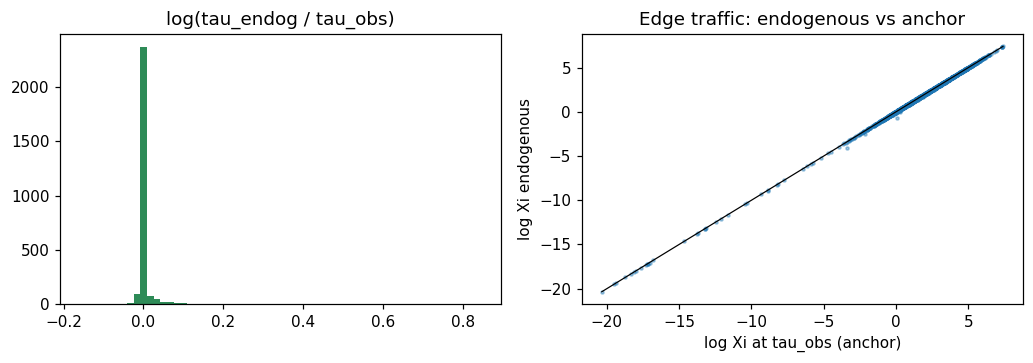

In [9]:
# ———— 检查点 5：基线 ————
r_tau = base_endog["tau_min_kl"] / TAU_OBS
print(f"Wbar: exogenous = {base_exog['Wbar']:.6f}   endogenous = {base_endog['Wbar']:.6f}")
print(f"endogenous: n_outer = {base_endog['n_outer']}, 收敛 = {base_endog['converged']}")
print(f"内生 τ / τ_obs: median = {np.median(r_tau):.5f}, mean = {r_tau.mean():.5f}, "
      f"p5 = {np.quantile(r_tau, .05):.4f}, p95 = {np.quantile(r_tau, .95):.4f}  (anchored 下应≈1)")

_ref = DATA_WORK / "outputs/stage2_endogenous_edgeproj_v2_lcc_gate5_bpr_pos05_v1/baseline_summary.json"
if _ref.exists():
    _r = json.loads(_ref.read_text())
    print(f"主线对照: Wbar_exog {_r['baseline_exogenous']['Wbar']:.6f} | "
          f"Wbar_endog {_r['baseline_endogenous']['Wbar']:.6f} | n_outer {_r['baseline_endogenous']['n_outer']}")

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
ax[0].hist(np.log(r_tau), bins=60, color="seagreen")
ax[0].set_title("log(tau_endog / tau_obs)")
ax[1].scatter(np.log(XI_OBS), np.log(base_endog["Xi_kl"]), s=4, alpha=.4)
lims = [np.log(XI_OBS).min(), np.log(XI_OBS).max()]
ax[1].plot(lims, lims, "k-", lw=.8)
ax[1].set_xlabel("log Xi at tau_obs (anchor)"); ax[1].set_ylabel("log Xi endogenous")
ax[1].set_title("Edge traffic: endogenous vs anchor")
plt.tight_layout(); plt.show()

## 第 6 部分 — λ 截面诊断（v4 §6.3，仅诊断）

$\ln(\tau^{obs}/\tau^{ff})=\lambda\,\ln(\hat\Xi/n)+\eta+\varepsilon$，车道整数分箱去均值。$\hat\Xi$ 是模型隐含量（循环性），估出的 $\hat\lambda$ 不回写参数。

In [10]:
# ============================================================================
# 第 6 部分 —— Step 3: λ 截面诊断（§6.3，仅诊断，不回写参数）
#   ln(τ^obs/τ^ff)_kl = λ·ln(Ξ̂_kl/n_kl) + η_kl + ε，车道整数分箱去均值吸收 η
# ============================================================================
y = np.log(np.clip(TAU_OBS / TAU_FF, EPS, None))
x = np.log(np.clip(base_endog["Xi_kl"] / np.clip(N_KL, 1e-9, None), EPS, None))
bins = np.round(N_KL).astype(int)
dfl = pd.DataFrame({"y": y, "x": x, "bin": bins})
dfl["y_r"] = dfl["y"] - dfl.groupby("bin")["y"].transform("mean")
dfl["x_r"] = dfl["x"] - dfl.groupby("bin")["x"].transform("mean")
yr, xr = dfl["y_r"].to_numpy(), dfl["x_r"].to_numpy()
okl = np.isfinite(yr) & np.isfinite(xr)
yr, xr = yr[okl], xr[okl]
xtx = float((xr * xr).sum())
lam_hat = float((xr * yr).sum() / xtx)
res = yr - lam_hat * xr
sse, sst = float((res * res).sum()), float((yr * yr).sum())
LAMBDA_DIAG = {"lambda_hat": lam_hat,
               "se": float(np.sqrt(sse / max(len(yr) - 1, 1) / xtx)),
               "r2": 1.0 - sse / sst if sst > 0 else float("nan"),
               "n_obs": int(len(yr)),
               "method": "OLS, lane-bin demeaned, model-implied Xi_hat",
               "notes": "Diagnostic only — see v4.tex §6.3; not used to override parameters.lambda_."}
log(f"Step 3(诊断): lambda_hat={lam_hat:.6f}")

[     3.1s] Step 3(诊断): lambda_hat=0.004691


{'lambda_hat': 0.004691, 'se': 0.00183, 'r2': 0.002481, 'n_obs': 2642, 'method': 'OLS, lane-bin demeaned, model-implied Xi_hat'}


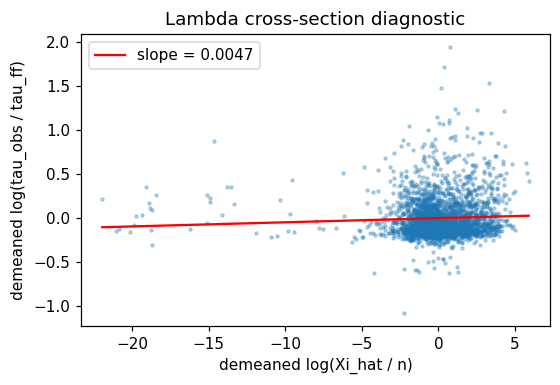

In [11]:
# ———— 检查点 6：λ 诊断散点 ————
print({k: (round(v, 6) if isinstance(v, float) else v) for k, v in LAMBDA_DIAG.items() if k != "notes"})
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.scatter(xr, yr, s=4, alpha=.3)
_g = np.linspace(xr.min(), xr.max(), 10)
ax.plot(_g, LAMBDA_DIAG["lambda_hat"] * _g, "r-", lw=1.5,
        label=f"slope = {LAMBDA_DIAG['lambda_hat']:.4f}")
ax.set_xlabel("demeaned log(Xi_hat / n)"); ax.set_ylabel("demeaned log(tau_obs / tau_ff)")
ax.legend(); ax.set_title("Lambda cross-section diagnostic")
plt.tight_layout(); plt.show()

## 第 7–8 部分 — 对比指标与 tidal 选边（score_bpr_st）

In [12]:
# ============================================================================
# 第 7 部分 —— 对比指标（= fixed_tau_model.comparison_summary + Stage2 附加列）
# ============================================================================
def predicted_od_shares(eq, abar_theta):
    """条件工作地选择（Fréchet）：pr(j|i) ∝ τ_ij^{-θ}·Ā_jθ·(l_j^F)^{αθ}，
       OD 份额 = l_i^R · pr(j|i)。"""
    wgt = eq["tau_inv"] * (abar_theta * eq["l_F"] ** (ALPHA * THETA))[None, :]
    return eq["l_R"][:, None] * (wgt / np.clip(wgt.sum(axis=1), EPS, None)[:, None])

def summarise(base, scen):
    """一行对比指标；键的顺序与原 CSV 完全一致。OD 加权双边成本用
       τ_ij = (τ_ij^{-θ})^{-1/θ}（分钟）。"""
    vR = (base["l_R"] > EPS) & (scen["l_R"] > EPS)
    vF = (base["l_F"] > EPS) & (scen["l_F"] > EPS)
    dlR = np.log(scen["l_R"][vR]) - np.log(base["l_R"][vR])
    dlF = np.log(scen["l_F"][vF]) - np.log(base["l_F"][vF])
    od_b = predicted_od_shares(base, ABAR)
    od_s = predicted_od_shares(scen, ABAR)
    tau_b = float(np.sum(od_b * np.clip(base["tau_inv"], EPS, None) ** (-1.0 / THETA)) / np.clip(od_b.sum(), EPS, None))
    tau_s = float(np.sum(od_s * np.clip(scen["tau_inv"], EPS, None) ** (-1.0 / THETA)) / np.clip(od_s.sum(), EPS, None))
    return {
        "base_label": base["label"], "scenario_label": scen["label"],
        "Wbar_base": base["Wbar"], "Wbar_scenario": scen["Wbar"],
        "Wbar_pct_change": 100.0 * (scen["Wbar"] / base["Wbar"] - 1.0),
        "residence_dissimilarity_pct": 100.0 * 0.5 * float(np.sum(np.abs(scen["l_R"] - base["l_R"]))),
        "workplace_dissimilarity_pct": 100.0 * 0.5 * float(np.sum(np.abs(scen["l_F"] - base["l_F"]))),
        "max_abs_log_residence_change": float(np.max(np.abs(dlR))),
        "p95_abs_log_residence_change": float(np.quantile(np.abs(dlR), 0.95)),
        "max_abs_log_workplace_change": float(np.max(np.abs(dlF))),
        "p95_abs_log_workplace_change": float(np.quantile(np.abs(dlF), 0.95)),
        "mean_edge_tau_pct_change": 100.0 * float(np.mean(scen["tau_min_kl"] / np.clip(base["tau_min_kl"], EPS, None) - 1.0)),
        "p95_abs_edge_log_tau_change": float(np.quantile(np.abs(np.log(scen["tau_min_kl"] / np.clip(base["tau_min_kl"], EPS, None))), 0.95)),
        "base_converged": bool(base["converged"]), "scenario_converged": bool(scen["converged"]),
        "base_iter": int(base["n_outer"]), "scenario_iter": int(scen["n_outer"]),
        "kappa": KAPPA,
        "od_dissimilarity_pct": 100.0 * 0.5 * float(np.sum(np.abs(od_s - od_b))),
        "base_od_weighted_bilateral_cost_min": tau_b,
        "scenario_od_weighted_bilateral_cost_min": tau_s,
        "od_weighted_bilateral_cost_pct_change": 100.0 * (tau_s / tau_b - 1.0),
        "label_baseline": base["label"], "label_scenario": scen["label"],
        "endogenous_congestion": scen["endogenous"],
        "mean_Xi_pct_change": 100.0 * float(np.mean(scen["Xi_kl"] / np.clip(base["Xi_kl"], EPS, None) - 1.0)),
        "p95_abs_log_Pi_change": float(np.quantile(np.abs(np.log(np.clip(scen["Pi_i"], EPS, None) / np.clip(base["Pi_i"], EPS, None))), 0.95)),
    }

In [13]:
# ============================================================================
# 第 8 部分 —— 互逆边对与 tidal 选边（score_bpr_st，主线）
# ============================================================================
_PAIR_IDX = {(int(EDGE_I[k]), int(EDGE_J[k])): k for k in range(M)}

def reciprocal_pairs():
    """全部互逆有向边对，返回 [(a,b)]，a<b，按首次出现（=a 升序）排列。"""
    out, seen = [], set()
    for k in range(M):
        r = _PAIR_IDX.get((int(EDGE_J[k]), int(EDGE_I[k])))
        if r is None:
            continue
        a, b = (k, r) if k < r else (r, k)
        if (a, b) in seen:
            continue
        seen.add((a, b))
        out.append((a, b))
    return out

RECIP_PAIRS = reciprocal_pairs()

def select_pairs_bpr_st(top_k, delta, xi):
    """主线 tidal 选边（rank=score_bpr_st）：
       资格：双向长度≥200m，快向减 delta 后 ≥1 车道；
       分数（一阶 BPR-ST）：Ξ_s·(τ_s^obs-τ_s^ff)_+ − Ξ_f·(τ_f^obs-τ_f^ff)_+；
       取分数最高的 top_k 对。返回 [(slow,fast)], [asym]。"""
    scored = []
    for a, b in RECIP_PAIRS:
        slow, fast = (a, b) if TAU_OBS[a] >= TAU_OBS[b] else (b, a)
        if min(ELL_KM[slow], ELL_KM[fast]) * 1000.0 < PAIR_MIN_LEN_M:
            continue
        if N_KL[fast] - delta < 1.0:
            continue
        asym = float(TAU_OBS[slow] / max(TAU_OBS[fast], 1e-9))
        score = (float(xi[slow]) * max(float(TAU_OBS[slow] - TAU_FF[slow]), 0.0)
                 - float(xi[fast]) * max(float(TAU_OBS[fast] - TAU_FF[fast]), 0.0))
        scored.append((slow, fast, asym, score))
    scored.sort(key=lambda r: -r[3])         # 稳定排序，平分保持入表次序
    top = scored[:top_k]
    return [(s, f) for s, f, _, _ in top], [a for _, _, a, _ in top]

def selected_pairs_frame(pairs, asyms):
    return pd.DataFrame([{
        "slow_edge_idx": int(s), "fast_edge_idx": int(f),
        "slow_i": int(EDGE_I[s]), "slow_j": int(EDGE_J[s]),
        "fast_i": int(EDGE_I[f]), "fast_j": int(EDGE_J[f]),
        "tau_slow_min": float(TAU_OBS[s]), "tau_fast_min": float(TAU_OBS[f]),
        "n_slow_pre": float(N_KL[s]), "n_fast_pre": float(N_KL[f]),
        "asym_ratio": float(a),
    } for (s, f), a in zip(pairs, asyms)])

def symmetric_tau(method):
    """CF1 对称化：互逆边对 τ 替换为 geometric=√(τ_ij·τ_ji) 或 arithmetic 均值。"""
    tau = TAU_OBS.copy()
    for a, b in RECIP_PAIRS:
        s = float(np.sqrt(TAU_OBS[a] * TAU_OBS[b])) if method == "geometric" \
            else 0.5 * float(TAU_OBS[a] + TAU_OBS[b])
        tau[a] = s
        tau[b] = s
    return tau

## 第 9 部分 — 输出目录与基线文件落盘

In [14]:
# ============================================================================
# 第 9 部分 —— 输出目录 + 基线文件
# ============================================================================
OUT.mkdir(parents=True, exist_ok=True)
CF_DIR = OUT / "counterfactuals"
CF_DIR.mkdir(parents=True, exist_ok=True)

(OUT / "parameters.json").write_text(json.dumps({
    "theta": THETA, "alpha": ALPHA, "beta": BETA,
    "lambda_phys": LAMBDA_PHYS, "lambda": LAMBDA_LEGACY, "delta1_source": DELTA1_AA,
    "theta_source": "AA(2022) Seattle, via Ahlfeldt et al. (2015)",
    "alpha_source": "Literature mid-range gross production spillover (mainline pos05)",
    "beta_source": "AA(2022) Seattle beta held",
    "lambda_phys_source": "Beijing speed-density evidence, elasticity ~1.1 (mainline)",
    "lambda_source": "LEGACY exog-only: delta1/theta with delta1=0.488 (AA 2022 Seattle)",
}, indent=2))
(OUT / "mainline_config.json").write_text(json.dumps({
    "congestion_form": "anchored", "congestion_lambda": LAMBDA_PHYS,
    "pair_selection": "score_bpr_st",
    "travel_cost": "raw_connected_v1 edgeproj_v2 gate5",
    "solver": {"damping": DAMPING, "max_outer": MAX_OUTER, "tol": TOL_OUTER, "kappa": KAPPA},
}, indent=2))

pdir = OUT / "primitives"; pdir.mkdir(exist_ok=True)
(pdir / "primitives_meta.json").write_text(json.dumps({
    "version_id": VERSION_ID, "grid_type": GRID_TYPE, "period": PERIOD,
    "od_pop_col": OD_POP_COL, "n_nodes": int(N), "n_edges": int(M), "Lbar": LBAR,
}, indent=2))
pd.DataFrame({"node_idx": np.arange(N), "grid_id": GRID_IDS,
              "L_R_obs": L_R_OBS, "L_F_obs": L_F_OBS}).to_csv(pdir / "primitives_nodes.csv", index=False)
pd.DataFrame({"edge_i": EDGE_I, "edge_j": EDGE_J, "ell_kl_km": ELL_KM,
              "v0_kl": ELL_KM / TAU_FF, "v_obs_kl": ELL_KM / TAU_OBS,
              "tau_ff_min": TAU_FF, "tau_obs_min": TAU_OBS,
              "n_kl": N_KL}).to_csv(pdir / "primitives_edges.csv", index=False)

fdir = OUT / "fundamentals"; fdir.mkdir(exist_ok=True)
np.savez_compressed(fdir / "fundamentals_arrays.npz", ubar_theta=UBAR, abar_theta=ABAR,
                    resid_R=RESID_R, resid_F=RESID_F)
(fdir / "fundamentals_meta.json").write_text(json.dumps({
    "chi": CHI, "kappa": KAPPA, "n_iter": inv_it,
    "converged": inv_converged, "max_log_change": inv_delta}, indent=2, default=float))

write_eq(base_exog, OUT / "baseline_exogenous_tau")
write_eq(base_endog, OUT / "baseline_endogenous")
(OUT / "lambda_diagnostic.json").write_text(json.dumps(LAMBDA_DIAG, indent=2))

baseline_summary = {
    "version_id": VERSION_ID, "lambda_used": LAMBDA_LEGACY,
    "lambda_source": "delta1/theta with delta1=0.488 (AA 2022 Seattle)",
    "congestion_form": "anchored", "congestion_lambda": LAMBDA_PHYS,
    "pair_selection": "score_bpr_st",
    "travel_cost": "raw_connected_v1 edgeproj_v2 gate5",
    "baseline_exogenous": {"Wbar": base_exog["Wbar"], "converged": base_exog["converged"]},
    "baseline_endogenous": {
        "Wbar": base_endog["Wbar"], "converged": base_endog["converged"],
        "n_outer": base_endog["n_outer"], "max_log_change": base_endog["max_log_change"],
        "mean_tau_vs_obs_pct": 100.0 * float(base_endog["tau_min_kl"].mean() / TAU_OBS.mean() - 1.0),
        "median_tau_ratio_vs_obs": float(np.median(base_endog["tau_min_kl"] / TAU_OBS)),
    },
    "lambda_diagnostic_hat_at_this_lambda": LAMBDA_DIAG["lambda_hat"],
}
(OUT / "baseline_summary.json").write_text(json.dumps(baseline_summary, indent=2, default=float))

717

## 第 10 部分 — Policy 反事实（5 政策 × exog/endog）

τ 类政策：exog 直接缩放 $\tau^{obs}$；endog 缩放 $\tau^{ff}$ 后由 (E6) 重新均衡。生产率/宜居度政策：直接乘 $\bar A^\theta,\ \bar u^\theta$。

In [15]:
# ============================================================================
# 第 10 部分 —— Policy 反事实（5 个政策 × exogenous / endogenous）
#   hub:   工作人数 ≥ 其正值 75 分位的节点；边只要一端碰 hub 即受冲击
#   outer: 距就业加权网格重心距离 ≥（有居民节点的）75 分位
# ============================================================================
log("Step 10: policy 反事实")
HUB = L_F_OBS >= float(np.quantile(L_F_OBS[L_F_OBS > 0], 0.75))
_xy = [g.split("_") for g in GRID_IDS]
XS = np.array([int(p[1]) if len(p) >= 3 else 0 for p in _xy], float)
YS = np.array([int(p[2]) if len(p) >= 3 else 0 for p in _xy], float)
_wt = np.clip(L_F_OBS, EPS, None)
DIST = np.hypot(XS - np.average(XS, weights=_wt), YS - np.average(YS, weights=_wt))
OUTER_RING = DIST >= float(np.quantile(DIST[L_R_OBS > 0], 0.75))
HUB_EDGE = HUB[EDGE_I] | HUB[EDGE_J]
OUTER_EDGE = OUTER_RING[EDGE_I] | OUTER_RING[EDGE_J]

POLICIES = [                                   # 与 default_policies() 一致
    ("uniform_speed_10pct", {"tau_scale": 0.90}),
    ("hub_access_15pct", {"tau_hub": 0.85}),
    ("hub_productivity_10pct", {"abar_hub": 1.10}),
    ("outer_ring_amenity_10pct", {"ubar_outer": 1.10}),
    ("fringe_transport_20pct", {"tau_outer": 0.80}),
]

policy_rows = []
for name, p in POLICIES:
    # 冲击后的 τ（exog 用）、τ^ff（endog 用）与 fundamentals
    tau_cf = TAU_OBS.copy() * p.get("tau_scale", 1.0)
    tau_ff_cf = TAU_FF.copy() * p.get("tau_scale", 1.0)
    if "tau_hub" in p:
        tau_cf[HUB_EDGE] *= p["tau_hub"]; tau_ff_cf[HUB_EDGE] *= p["tau_hub"]
    if "tau_outer" in p:
        tau_cf[OUTER_EDGE] *= p["tau_outer"]; tau_ff_cf[OUTER_EDGE] *= p["tau_outer"]
    ubar_cf = UBAR.copy(); abar_cf = ABAR.copy()
    if "abar_hub" in p:
        abar_cf[HUB] *= p["abar_hub"]
    if "ubar_outer" in p:
        ubar_cf[OUTER_RING] *= p["ubar_outer"]

    eq_x = solve_cached(f"policy_{name}_exog", ubar_theta=ubar_cf, abar_theta=abar_cf, chi=CHI,
                        tau_min_init=tau_cf, endogenous=False, label=f"{name}_exogenous_tau")
    row = summarise(base_exog, eq_x); row.update({"policy": name, "congestion_mode": "exogenous_tau"})
    policy_rows.append(row)

    eq_n = solve_cached(f"policy_{name}_endog", ubar_theta=ubar_cf, abar_theta=abar_cf, chi=CHI,
                        tau_ff=tau_ff_cf, tau_min_init=TAU_OBS.copy(), endogenous=True,
                        label=f"{name}_endogenous")
    row = summarise(base_endog, eq_n); row.update({"policy": name, "congestion_mode": "endogenous"})
    policy_rows.append(row)
    log(f"  policy {name}: exog {policy_rows[-2]['Wbar_pct_change']:+.4f}% | "
        f"endog {row['Wbar_pct_change']:+.4f}% (n_outer={eq_n['n_outer']})")
pd.DataFrame(policy_rows).to_csv(CF_DIR / "policy_cf_all_modes.csv", index=False)

[     3.2s] Step 10: policy 反事实


[     3.4s]   policy uniform_speed_10pct: exog +1.5567% | endog +0.0073% (n_outer=64)


[     3.6s]   policy hub_access_15pct: exog +2.2341% | endog +0.0038% (n_outer=65)


[     3.7s]   policy hub_productivity_10pct: exog +1.1935% | endog +1.1701% (n_outer=65)


[     3.9s]   policy outer_ring_amenity_10pct: exog +0.0895% | endog +0.0943% (n_outer=65)


[     4.1s]   policy fringe_transport_20pct: exog +0.1466% | endog +0.0012% (n_outer=65)


,policy,congestion_mode,Wbar_pct_change,residence_dissimilarity_pct,od_weighted_bilateral_cost_pct_change,scenario_iter,scenario_converged
0,uniform_speed_10pct,exogenous_tau,1.5567,2.2621,-2.2793,1,True
1,uniform_speed_10pct,endogenous,0.0073,0.0252,-0.0488,64,True
2,hub_access_15pct,exogenous_tau,2.2341,3.7095,-1.0369,1,True
3,hub_access_15pct,endogenous,0.0038,0.0133,-0.0212,65,True
4,hub_productivity_10pct,exogenous_tau,1.1935,0.7810,0.0381,1,True
5,hub_productivity_10pct,endogenous,1.1701,0.7198,-0.0873,65,True
6,outer_ring_amenity_10pct,exogenous_tau,0.0895,0.4118,0.1607,1,True
7,outer_ring_amenity_10pct,endogenous,0.0943,0.3617,0.2120,65,True
8,fringe_transport_20pct,exogenous_tau,0.1466,0.7041,-1.2161,1,True
9,fringe_transport_20pct,endogenous,0.0012,0.0051,-0.0100,65,True


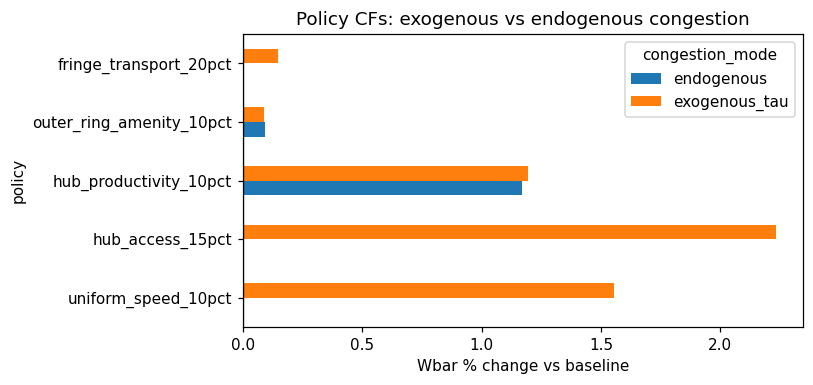

要点: τ 类政策 exog 收益大、endog 后大幅缩水（诱增流量吃掉时间节省）；生产率/宜居度政策两种模式接近。


In [16]:
# ———— 检查点 10：policy 福利对比 ————
dfp = pd.DataFrame(policy_rows)
display(dfp[["policy", "congestion_mode", "Wbar_pct_change", "residence_dissimilarity_pct",
             "od_weighted_bilateral_cost_pct_change", "scenario_iter", "scenario_converged"]].round(4))
_w = dfp.pivot(index="policy", columns="congestion_mode", values="Wbar_pct_change")
_w = _w.loc[[p for p, _ in POLICIES]]
ax = _w.plot.barh(figsize=(7.5, 3.6))
ax.set_xlabel("Wbar % change vs baseline"); ax.set_title("Policy CFs: exogenous vs endogenous congestion")
ax.axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.show()
print("要点: τ 类政策 exog 收益大、endog 后大幅缩水（诱增流量吃掉时间节省）；"
      "生产率/宜居度政策两种模式接近。")

## 第 11–12 部分 — 结构反事实 CF1/CF2/CF3（endog + exog）

CF1 对称化（方向性的价值）；CF2 tidal top50 ±1 车道；CF3 均匀扩容（endog）/均匀提速（exog）。

注意（与原代码一致的隐藏差异）：CF2/CF3 endog 从 $\tau^{ff}$ 起步，tidal/policy endog 从 $\tau^{obs}$ 起步。

In [17]:
# ============================================================================
# 第 11 部分 —— 结构反事实 CF1 / CF2 / CF3（endogenous）
#   CF1: τ 对称化后作为初值重新内生求解（几何为主，算术只跑 CF1）
#   CF2: tidal top50 (+1 慢向 / -1 快向)，从 τ^ff 起步（原 run_cf2_tidal 未传初值）
#   CF3: n×{1.10,1.25,1.50}，同样从 τ^ff 起步
# ============================================================================
log("Step 11: 结构反事实 (endogenous)")
struct_rows = []
for method in ("geometric", "arithmetic"):
    eq1 = solve_cached(f"CF1_symmetric_{method}", ubar_theta=UBAR, abar_theta=ABAR, chi=CHI,
                       tau_min_init=symmetric_tau(method), endogenous=True,
                       label=f"CF1_symmetric_{method}")
    row = summarise(base_endog, eq1)
    row.update({"cf": f"CF1_symmetric_{method}", "congestion_mode": "endogenous"})
    struct_rows.append(row)
    log(f"  CF1 {method}: {row['Wbar_pct_change']:+.6f}%")

pairs50, asym50 = select_pairs_bpr_st(50, 1.0, base_endog["Xi_kl"])
n_cf2 = N_KL.copy()
for s, f in pairs50:
    n_cf2[s] += 1.0; n_cf2[f] -= 1.0
eq2 = solve_cached("CF2_tidal_top50_endog", ubar_theta=UBAR, abar_theta=ABAR, chi=CHI,
                   tau_min_init=TAU_FF.copy(), endogenous=True, n_kl=n_cf2)  # label 默认 "equilibrium"（原样）
row = summarise(base_endog, eq2)
row.update({"cf": "CF2_tidal_top50", "congestion_mode": "endogenous",
            "n_pairs": len(pairs50), "pair_selection": "score_bpr_st"})
struct_rows.append(row)
log(f"  CF2 top50: {row['Wbar_pct_change']:+.4f}%")

for fac in (1.10, 1.25, 1.50):
    eq3 = solve_cached(f"CF3_uniform_{fac:.2f}_endog", ubar_theta=UBAR, abar_theta=ABAR, chi=CHI,
                       tau_min_init=TAU_FF.copy(), endogenous=True, n_kl=N_KL * fac)
    row = summarise(base_endog, eq3)
    row.update({"cf": f"CF3_uniform_{fac:.2f}", "congestion_mode": "endogenous"})
    struct_rows.append(row)
    log(f"  CF3 x{fac}: {row['Wbar_pct_change']:+.4f}%")

# 行序与原 CSV 一致：geo CF1, CF2, CF3×3, 最后补 arithmetic CF1
_order = [0, 2, 3, 4, 5, 1]
pd.DataFrame([struct_rows[i] for i in _order]).to_csv(
    CF_DIR / "structural_cf_endogenous.csv", index=False)

[     4.3s] Step 11: 结构反事实 (endogenous)


[     4.3s]   CF1 geometric: -0.000019%


[     4.4s]   CF1 arithmetic: -0.000019%


[     4.5s]   CF2 top50: +0.2252%


[     4.6s]   CF3 x1.1: +0.3951%


[     4.7s]   CF3 x1.25: +0.9191%


[     4.8s]   CF3 x1.5: +1.6250%


In [18]:
# ============================================================================
# 第 12 部分 —— 结构反事实 CF1 / CF2 / CF3（exogenous τ，测量口径）
#   CF1: τ 固定在对称化表（隔离"双边成本测量"效应）
#   CF2: 选边同上（但用 exog 基线的 Ξ），τ 按 BPR 在固定 Ξ 下重算，δ1=0.488
#   CF3: τ→τ/factor 的均匀提速（测量问题；区别于 endog 的产能冲击）
# ============================================================================
log("Step 12: 结构反事实 (exogenous)")
exog_rows = []
eq1x = solve_cached("CF1_symmetric_geometric_exog", ubar_theta=UBAR, abar_theta=ABAR, chi=CHI,
                    tau_min_init=symmetric_tau("geometric"), endogenous=False,
                    label="CF1_symmetric_geometric_exog")
row = summarise(base_exog, eq1x)
row.update({"cf": "CF1_symmetric_geometric", "congestion_mode": "exogenous_tau"})
exog_rows.append(row)

pairs50x, _ = select_pairs_bpr_st(50, 1.0, base_exog["Xi_kl"])
tau_cf2x = TAU_OBS.copy()
for s, f in pairs50x:
    for idx, d_n in ((s, 1.0), (f, -1.0)):
        n_new = max(float(N_KL[idx]) + d_n, 0.25)
        tau_cf2x[idx] = max(TAU_FF[idx] * (float(base_exog["Xi_kl"][idx]) / max(n_new, EPS)) ** DELTA1_CF2_EXOG,
                            TAU_FF[idx])
eq2x = solve_cached("CF2_tidal_top50_exog", ubar_theta=UBAR, abar_theta=ABAR, chi=CHI,
                    tau_min_init=tau_cf2x, endogenous=False, label="CF2_tidal_top50_exog")
row = summarise(base_exog, eq2x)
row.update({"cf": "CF2_tidal_top50", "congestion_mode": "exogenous_tau",
            "n_pairs": len(pairs50x), "pair_selection": "score_bpr_st"})
exog_rows.append(row)

for fac in (1.10, 1.25, 1.50):
    eq3x = solve_cached(f"CF3_uniform_{fac:.2f}_exog", ubar_theta=UBAR, abar_theta=ABAR, chi=CHI,
                        tau_min_init=TAU_OBS / fac, endogenous=False,
                        label=f"CF3_uniform_{fac:.2f}_exog")
    row = summarise(base_exog, eq3x)
    row.update({"cf": f"CF3_uniform_{fac:.2f}", "congestion_mode": "exogenous_tau"})
    exog_rows.append(row)
pd.DataFrame(exog_rows).to_csv(CF_DIR / "structural_cf_exogenous.csv", index=False)

[     4.8s] Step 12: 结构反事实 (exogenous)


In [19]:
# ———— 检查点 11/12：结构 CF ————
dfs = pd.DataFrame(struct_rows); dfx = pd.DataFrame(exog_rows)
display(dfs[["cf", "Wbar_pct_change", "residence_dissimilarity_pct", "scenario_iter"]].round(4))
display(dfx[["cf", "Wbar_pct_change", "od_weighted_bilateral_cost_pct_change"]].round(4))
print(f"CF1 endog ≈ 0（{dfs.loc[dfs.cf.str.startswith('CF1'), 'Wbar_pct_change'].round(6).tolist()}%）："
      "anchored 拥堵下对称化初值会被吸回同一不动点，方向性的量化要靠 exog 口径与 symmetry suite。")
print(f"CF2 endog +{dfs.loc[dfs.cf == 'CF2_tidal_top50', 'Wbar_pct_change'].iloc[0]:.4f}% "
      f"vs tidal_top50 LT（第 13 部分）应几乎相同 —— 起步 τ 不同但不动点相同。")

,cf,Wbar_pct_change,residence_dissimilarity_pct,scenario_iter
0,CF1_symmetric_geometric,-0.0000,0.0001,65
1,CF1_symmetric_arithmetic,-0.0000,0.0001,67
2,CF2_tidal_top50,0.2252,0.6783,56
3,CF3_uniform_1.10,0.3951,0.4511,60
4,CF3_uniform_1.25,0.9191,1.0725,60
5,CF3_uniform_1.50,1.6250,1.9642,62


,cf,Wbar_pct_change,od_weighted_bilateral_cost_pct_change
0,CF1_symmetric_geometric,1.0987,0.1264
1,CF2_tidal_top50,-1.4725,-0.7689
2,CF3_uniform_1.10,1.3868,-2.0878
3,CF3_uniform_1.25,4.0159,-3.8111
4,CF3_uniform_1.50,10.6315,-2.3376


CF1 endog ≈ 0（[-1.9e-05, -1.9e-05]%）：anchored 拥堵下对称化初值会被吸回同一不动点，方向性的量化要靠 exog 口径与 symmetry suite。
CF2 endog +0.2252% vs tidal_top50 LT（第 13 部分）应几乎相同 —— 起步 τ 不同但不动点相同。


## 第 13 部分 — Tidal endogenous（主线潮汐结果）

短期＝份额钉在基线（只有交通重配），长期＝完全重新分选（sorting 吸收部分收益）。

In [20]:
# ============================================================================
# 第 13 部分 —— Tidal endogenous（主线潮汐结果）
#   specs: (top50, Δ=1), (top50, Δ=0.5), (top100, Δ=1) × {short_run, long_run}
#   短期：份额钉在基线；长期：完全重新分选。τ 从 τ^obs 起步，anchored 反馈。
# ============================================================================
log("Step 13: tidal endogenous")
tidal_rows = []
for top_k, delta in ((50, 1.0), (50, 0.5), (100, 1.0)):
    pairs, asyms = select_pairs_bpr_st(top_k, delta, base_endog["Xi_kl"])
    n_cf = N_KL.copy()
    for s, f in pairs:
        n_cf[s] += delta; n_cf[f] -= delta
    for horizon in ("short_run", "long_run"):
        pin = dict(l_R_pin=base_endog["l_R"], l_F_pin=base_endog["l_F"]) if horizon == "short_run" else {}
        eq_t = solve_cached(f"tidal_top{top_k}_d{delta}_{horizon}",
                            ubar_theta=UBAR, abar_theta=ABAR, chi=CHI,
                            tau_min_init=TAU_OBS.copy(), endogenous=True, n_kl=n_cf,
                            label=f"tidal_top{top_k}_d{delta}_{horizon}", **pin)
        sub = CF_DIR / f"tidal_endog_top{top_k}_d{delta}_{horizon}"
        write_eq(eq_t, sub)
        if horizon == "long_run":
            selected_pairs_frame(pairs, asyms).to_csv(sub / "selected_pairs.csv", index=False)
        row = summarise(base_endog, eq_t)
        row.update({"cf": "tidal_lane_endogenous", "top_k": top_k, "delta_lanes": delta,
                    "horizon": horizon, "n_pairs": len(pairs),
                    "pair_selection": "score_bpr_st",
                    "congestion_form": "anchored", "congestion_lambda": LAMBDA_PHYS})
        tidal_rows.append(row)
        log(f"  tidal top{top_k} d{delta} {horizon}: {row['Wbar_pct_change']:+.4f}% "
            f"(n_outer={eq_t['n_outer']})")
pd.DataFrame(tidal_rows).to_csv(CF_DIR / "tidal_lane_endogenous_summary.csv", index=False)

[     5.3s] Step 13: tidal endogenous


[     5.4s]   tidal top50 d1.0 short_run: +0.6659% (n_outer=65)


[     5.5s]   tidal top50 d1.0 long_run: +0.2252% (n_outer=65)


[     5.6s]   tidal top50 d0.5 short_run: +0.3193% (n_outer=65)


[     5.8s]   tidal top50 d0.5 long_run: +0.1168% (n_outer=65)


[     5.9s]   tidal top100 d1.0 short_run: +0.8714% (n_outer=65)


[     6.0s]   tidal top100 d1.0 long_run: +0.3243% (n_outer=65)


,top_k,delta_lanes,horizon,n_pairs,Wbar_pct_change,residence_dissimilarity_pct,mean_edge_tau_pct_change
0,50,1.0,short_run,50,0.6659,0.0000,0.4055
1,50,1.0,long_run,50,0.2252,0.6783,0.2173
2,50,0.5,short_run,50,0.3193,0.0000,0.0985
3,50,0.5,long_run,50,0.1168,0.3527,0.0460
4,100,1.0,short_run,100,0.8714,0.0000,0.7656
5,100,1.0,long_run,100,0.3243,0.8637,0.5101


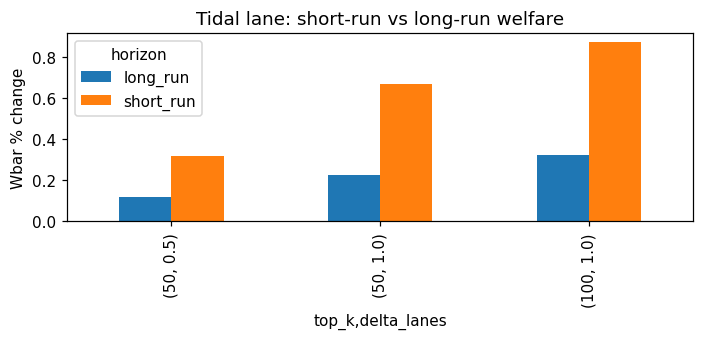

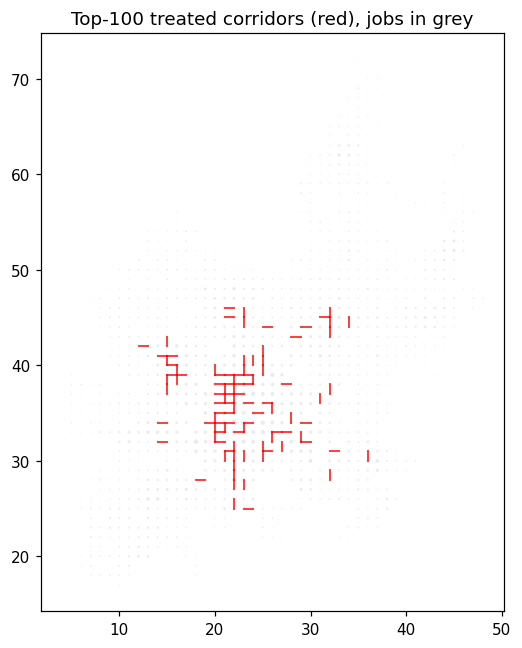

In [21]:
# ———— 检查点 13：tidal ST vs LT + 选边地图 ————
dft = pd.DataFrame(tidal_rows)
display(dft[["top_k", "delta_lanes", "horizon", "n_pairs", "Wbar_pct_change",
             "residence_dissimilarity_pct", "mean_edge_tau_pct_change"]].round(4))
_pv = dft.pivot_table(index=["top_k", "delta_lanes"], columns="horizon", values="Wbar_pct_change")
ax = _pv.plot.bar(figsize=(6.5, 3.2))
ax.set_ylabel("Wbar % change"); ax.set_title("Tidal lane: short-run vs long-run welfare")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(GX, GY, s=np.sqrt(L_F_OBS) * .3 + .1, alpha=.15, color="grey", lw=0)
for s, f in pairs:   # 最后一轮循环 = top100 选边
    ax.plot([GX[EDGE_I[s]], GX[EDGE_J[s]]], [GY[EDGE_I[s]], GY[EDGE_J[s]]], "r-", lw=1.2, alpha=.8)
ax.set_aspect("equal"); ax.set_title("Top-100 treated corridors (red), jobs in grey")
plt.tight_layout(); plt.show()

## 第 14 部分 — Tidal exogenous BPR 网格（Stage-1 复刻，固定 $\Xi$，δ1=0.488）

In [22]:
# ============================================================================
# 第 14 部分 —— Tidal exogenous BPR 网格（Stage-1 复刻：固定 Ξ 的 BPR，δ1=0.488）
#   选边（Spec-C）：互逆对按 τ 不对称比降序；门槛 min_asym_ratio、
#   min_fast_lanes=2、快向减 Δ 后 ≥1、双向长度 ≥200m。
#   冲击：Ξ_impl = n·(max(τ^obs,τ^ff)/τ^ff)^{1/δ1}；τ_new = max(τ^ff·(Ξ/n_new)^{δ1}, τ^ff)
#   direct 变体：τ_slow×s、τ_fast×f 直接缩放。
#   两个 horizon 都是固定 τ 求解：exogenous_tau（自由分选）/ short_run_fixed_shares（钉份额）
# ============================================================================
log("Step 14: tidal exogenous BPR 网格")
TIDAL_EXOG_SPECS = []
for top_n in (10, 25, 50, 100):
    for dl in (0.5, 1.0):
        TIDAL_EXOG_SPECS.append({"name": f"bpr_top{top_n}_d{str(dl).replace('.', 'p')}_r1p10",
                                 "top_n": top_n, "delta": dl, "min_ratio": 1.10, "method": "bpr"})
for r in (1.25, 1.50, 2.00):
    TIDAL_EXOG_SPECS.append({"name": f"bpr_top50_d1_r{str(r).replace('.', 'p')}",
                             "top_n": 50, "delta": 1.0, "min_ratio": r, "method": "bpr"})
for ss, fs in ((0.90, 1.10), (0.85, 1.15), (0.80, 1.20)):
    TIDAL_EXOG_SPECS.append({"name": f"direct_top50_s{str(ss).replace('.', '')}_f{str(fs).replace('.', '')}",
                             "top_n": 50, "delta": 1.0, "min_ratio": 1.10,
                             "method": "direct", "slow_scale": ss, "fast_scale": fs})

def select_pairs_specC(top_n, delta, min_ratio):
    """按不对称比降序取前 top_n 个合格互逆对（原 select_pairs）。"""
    pool = []
    for a, b in RECIP_PAIRS:
        if min(ELL_KM[a], ELL_KM[b]) * 1000.0 < PAIR_MIN_LEN_M:
            continue
        ratio = max(TAU_OBS[a], TAU_OBS[b]) / min(TAU_OBS[a], TAU_OBS[b])
        if ratio < min_ratio:
            continue
        pool.append((a, b, float(ratio)))
    pool.sort(key=lambda r: -r[2])
    picked = []
    for a, b, ratio in pool:
        if len(picked) >= top_n:
            break
        slow, fast = (a, b) if TAU_OBS[a] >= TAU_OBS[b] else (b, a)
        if N_KL[fast] < 2.0:                 # min_fast_lanes
            continue
        if N_KL[fast] - delta < 1.0:
            continue
        picked.append((slow, fast, ratio))
    return picked

tidal_exog_rows, edge_detail_parts = [], []
for spec in TIDAL_EXOG_SPECS:
    picked = select_pairs_specC(spec["top_n"], spec["delta"], spec["min_ratio"])
    tau_cf = TAU_OBS.copy()
    details = []
    for rank, (s, f, ratio) in enumerate(picked, start=1):
        n_s, n_f = float(N_KL[s]), float(N_KL[f])
        if spec["method"] == "bpr":
            n_s_new, n_f_new = n_s + spec["delta"], n_f - spec["delta"]
            xi_s = n_s * (max(TAU_OBS[s], TAU_FF[s]) / max(TAU_FF[s], EPS)) ** (1.0 / DELTA1_AA)
            xi_f = n_f * (max(TAU_OBS[f], TAU_FF[f]) / max(TAU_FF[f], EPS)) ** (1.0 / DELTA1_AA)
            tau_s_new = max(TAU_FF[s] * (xi_s / max(n_s_new, EPS)) ** DELTA1_AA, TAU_FF[s])
            tau_f_new = max(TAU_FF[f] * (xi_f / max(n_f_new, EPS)) ** DELTA1_AA, TAU_FF[f])
        else:                                # direct_tau
            n_s_new, n_f_new = n_s + spec["delta"], n_f - spec["delta"]
            tau_s_new = float(TAU_OBS[s]) * spec["slow_scale"]
            tau_f_new = float(TAU_OBS[f]) * spec["fast_scale"]
        tau_cf[s], tau_cf[f] = tau_s_new, tau_f_new
        details.append({
            "spec_name": spec["name"], "rank": rank, "method": spec["method"],
            "delta_lanes": spec["delta"], "asym_ratio": ratio,
            "edge_idx_slow": int(s), "edge_idx_fast": int(f),
            "slow_i": int(EDGE_I[s]), "slow_j": int(EDGE_J[s]),
            "grid_slow_i": str(GRID_IDS[EDGE_I[s]]), "grid_slow_j": str(GRID_IDS[EDGE_J[s]]),
            "tau_slow_obs": float(TAU_OBS[s]), "tau_fast_obs": float(TAU_OBS[f]),
            "tau_ff_slow": float(TAU_FF[s]), "tau_ff_fast": float(TAU_FF[f]),
            "lanes_slow": n_s, "lanes_fast": n_f,
            "lanes_slow_new": n_s_new, "lanes_fast_new": n_f_new,
            "tau_slow_new": float(tau_s_new), "tau_fast_new": float(tau_f_new),
            "tau_slow_pct_change": 100.0 * (float(tau_s_new) / float(TAU_OBS[s]) - 1.0),
            "tau_fast_pct_change": 100.0 * (float(tau_f_new) / float(TAU_OBS[f]) - 1.0),
        })
    for horizon in ("exogenous_tau", "short_run_fixed_shares"):
        pin = dict(l_R_pin=base_exog["l_R"], l_F_pin=base_exog["l_F"]) \
            if horizon == "short_run_fixed_shares" else {}
        eq_g = solve_cached(f"grid_{spec['name']}_{horizon}",
                            ubar_theta=UBAR, abar_theta=ABAR, chi=CHI,
                            tau_min_init=tau_cf, endogenous=False,
                            label=f"{spec['name']}_{horizon}", **pin)
        row = summarise(base_exog, eq_g)
        row.update({"policy_family": "tidal_lane_bpr_fixed_xi", "spec_name": spec["name"],
                    "horizon": horizon, "top_n": spec["top_n"],
                    "delta_lanes": spec["delta"], "n_pairs": len(picked)})
        tidal_exog_rows.append(row)
    edge_detail_parts.extend(details)
pd.DataFrame(tidal_exog_rows).to_csv(CF_DIR / "tidal_lane_exogenous_bpr_grid.csv", index=False)
pd.DataFrame(edge_detail_parts).to_csv(CF_DIR / "tidal_lane_exogenous_edge_detail.csv", index=False)

log(f"完成 — 输出在 {OUT}")
log(f"endogenous 基线 Wbar = {base_endog['Wbar']:.6f} | "
    f"median τ/τ_obs = {baseline_summary['baseline_endogenous']['median_tau_ratio_vs_obs']:.4f}")

[     6.1s] Step 14: tidal exogenous BPR 网格


[     8.6s] 完成 — 输出在 /sessions/gallant-vibrant-cannon/mnt/TidalLanes/data_work/outputs/estimation_flat_check_v1


[     8.6s] endogenous 基线 Wbar = 3.200092 | median τ/τ_obs = 1.0001


In [23]:
# ———— 检查点 14：网格汇总 ————
dfg = pd.DataFrame(tidal_exog_rows)
display(dfg.pivot_table(index="spec_name", columns="horizon", values="Wbar_pct_change").round(4))
print("完成。输出目录:", OUT)
print("与主线的逐项数值核对报告: outputs/estimation_flat_check_v1/COMPARISON_vs_mainline.md")

horizon,exogenous_tau,short_run_fixed_shares
spec_name,,
bpr_top100_d0p5_r1p10,0.0816,0.0817
bpr_top100_d1p0_r1p10,0.1569,0.1572
bpr_top10_d0p5_r1p10,0.0049,0.0049
bpr_top10_d1p0_r1p10,0.0091,0.0092
bpr_top25_d0p5_r1p10,0.0134,0.0134
bpr_top25_d1p0_r1p10,0.0254,0.0254
bpr_top50_d0p5_r1p10,0.0453,0.0454
bpr_top50_d1_r1p25,0.0881,0.0884
bpr_top50_d1_r1p5,0.0881,0.0884


完成。输出目录: /sessions/gallant-vibrant-cannon/mnt/TidalLanes/data_work/outputs/estimation_flat_check_v1
与主线的逐项数值核对报告: outputs/estimation_flat_check_v1/COMPARISON_vs_mainline.md
